# PPP Analysis

In [27]:
import os
import json
import numpy as np
import matplotlib.pyplot as plt

from pathlib import Path

VIS_DIR = Path("../ppp_vis")

In [28]:
from PIL import Image

def load_sample(prefix, vis_dir=VIS_DIR):
    """Lädt Heatmap, Bild, GT Instanzen, Zentren, Meta und das Visualizer-Bild."""
    prefix = vis_dir / prefix

    sample = {}

    # Heatmap
    sample["heatmap"] = np.load(str(prefix) + "_heatmap.npy")

    # RGB Image (gecropped, unnormalized)
    img_path = str(prefix) + "_img.npy"
    if os.path.exists(img_path):
        sample["img"] = np.load(img_path)
    else:
        sample["img"] = None

    # GT instance map
    inst_path = str(prefix) + "_gt_inst.npy"
    if os.path.exists(inst_path):
        sample["gt_inst"] = np.load(inst_path)
    else:
        sample["gt_inst"] = None

    # GT centers
    centers_path = str(prefix) + "_centers.npy"
    if os.path.exists(centers_path):
        sample["centers"] = np.load(centers_path)
    else:
        sample["centers"] = np.empty((0,2))

    # Meta information
    meta_path = str(prefix) + "_meta.json"
    if os.path.exists(meta_path):
        with open(meta_path, "r") as f:
            sample["meta"] = json.load(f)
    else:
        sample["meta"] = {}

    # ---- NEW: visualizer PNG ----
    vis_path = str(prefix) + "_vis.png"
    if os.path.exists(vis_path):
        sample["vis_image"] = np.array(Image.open(vis_path))
    else:
        sample["vis_image"] = None

    return sample

from pathlib import Path

def list_samples(vis_dir=VIS_DIR):
    """Return all sample prefixes (strings) based on *_heatmap.npy files."""
    prefixes = set()

    for f in vis_dir.iterdir():
        if f.name.endswith("_heatmap.npy"):
            prefix = f.name.replace("_heatmap.npy", "")
            prefixes.add(prefix)

    return sorted(prefixes)

In [29]:
from ipywidgets import Dropdown

prefixes = list_samples()

dropdown = Dropdown(options=prefixes, description="Sample:")
dropdown

Dropdown(description='Sample:', options=('00000000_aachen_000000_000019_leftImg8bit', '00000200_bremen_000130_…

In [74]:
prefix = dropdown.value
sample = load_sample(prefix)

heatmap = sample["heatmap"]
img = sample["img"]
gt_inst = sample["gt_inst"]
centers = sample["centers"]
meta = sample["meta"]

In [75]:
# if sample["vis_image"] is not None:
#     plt.figure(figsize=(20,10))
#     plt.imshow(sample["vis_image"])
#     plt.title("Visualizer Output (GT + Heatmap + Centers)")
#     plt.axis("off")
# else:
#     print("Keine visuelle PNG gefunden.")

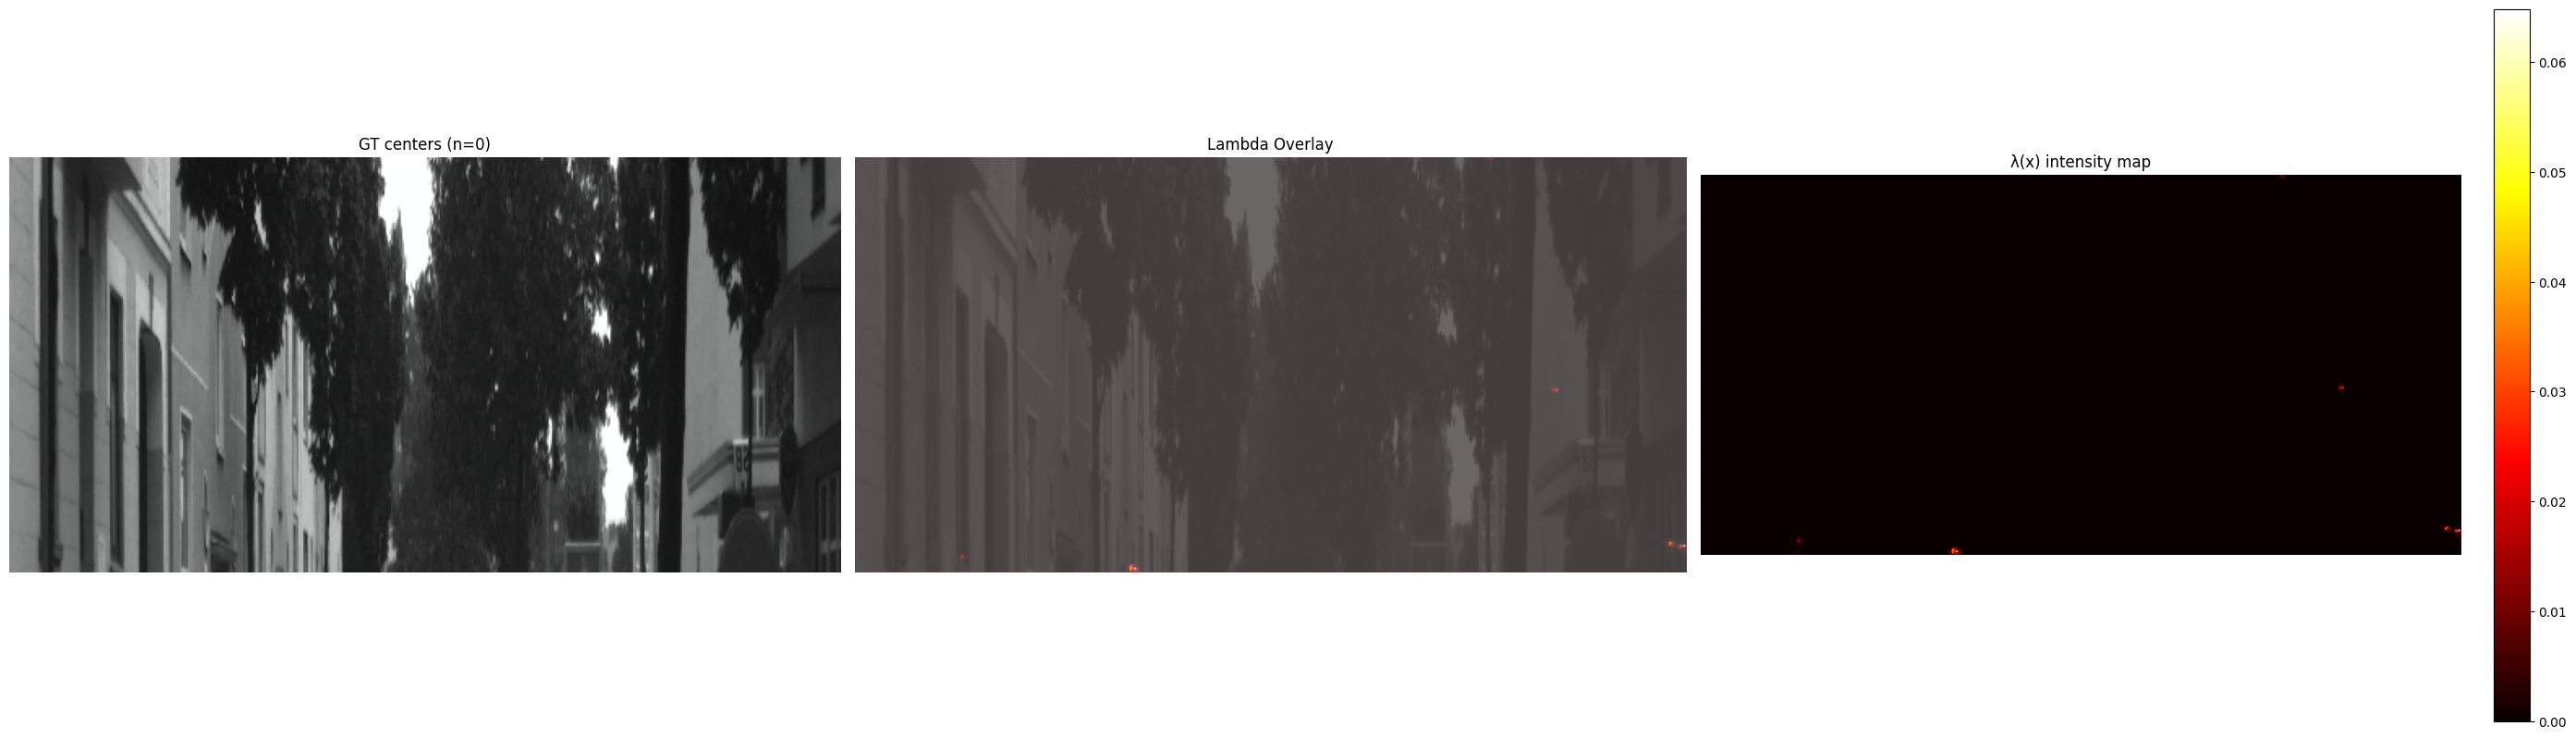

Expected count: 1.467
GT count: 0
Difference: +1.467


In [76]:
def show_lambda_tripanel(
    img_rgb,
    logits,
    centers,
    crop_size=(256,512),
    normalize=False,
    save_path=None,
    loss_text=""
):
    """
    Create a 3-panel visualization for lambda intensity:
      (1) image + GT centers
      (2) RGB + lambda overlay + centers (semi-transparent)
      (3) pure lambda map
    """

    H, W = logits.shape
    pixel_area = crop_size[0] * crop_size[1]

    # λ(x) = exp(logits) / pixel_area
    lam = np.exp(logits) / pixel_area

    if normalize:
        lam_disp = lam / lam.max() if lam.max() > 0 else lam
    else:
        lam_disp = lam

    plt.figure(figsize=(28, 8))

    # --------------------------------------------------
    # (1) GT centers
    # --------------------------------------------------
    plt.subplot(1, 3, 1)
    plt.imshow(img_rgb)
    plt.title(f"GT centers (n={len(centers)})")
    for (cx, cy) in centers:
        plt.plot(cx, cy, "rx", markersize=12, markeredgewidth=2, alpha=0.75)
    plt.axis("off")

    # --------------------------------------------------
    # (2) Overlay (image + lambda)
    # --------------------------------------------------
    plt.subplot(1, 3, 2)
    plt.imshow(img_rgb, alpha=0.45)
    plt.imshow(lam_disp, cmap="hot", alpha=0.60)
    for (cx, cy) in centers:
        plt.plot(cx, cy, "cx", markersize=12, markeredgewidth=2, alpha=0.6)
    plt.title("Lambda Overlay")
    plt.axis("off")

    # --------------------------------------------------
    # (3) Pure lambda
    # --------------------------------------------------
    plt.subplot(1, 3, 3)
    im = plt.imshow(lam_disp, cmap="hot")
    plt.title("λ(x) intensity map")
    plt.colorbar(im, fraction=0.046, pad=0.04)
    if loss_text:
        plt.text(
            10, 20, loss_text,
            color="white", fontsize=12,
            bbox=dict(facecolor="black", alpha=0.5)
        )
    plt.axis("off")

    plt.tight_layout()

    if save_path:
        plt.savefig(save_path)
        plt.close()
    else:
        plt.show()
    
    # metric
    expected_count = lam.sum()
    gt_count = len(centers)
    print(f"Expected count: {expected_count:.3f}")
    print(f"GT count: {gt_count}")
    print(f"Difference: {expected_count - gt_count:+.3f}")


show_lambda_tripanel(
    img,
    heatmap,  # logits
    centers,
    crop_size=(256,512),
    normalize=False
)


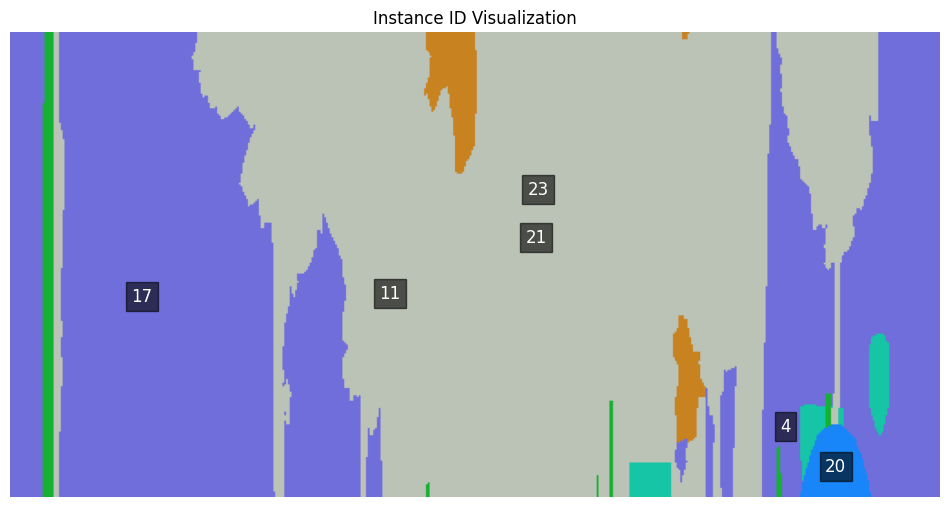

In [77]:
import matplotlib.pyplot as plt

def visualize_instance_ids(gt_inst):
    fig, ax = plt.subplots(figsize=(12, 8))

    # Colorize instance map
    colored = np.zeros((*gt_inst.shape, 3), dtype=np.uint8)
    ids = np.unique(gt_inst)
    rng = np.random.default_rng(42)

    centroids = {}

    for uid in ids:
        if uid == 0: continue
        mask = (gt_inst == uid)
        color = rng.integers(0, 255, size=3)
        colored[mask] = color

        ys, xs = np.where(mask)
        centroids[int(uid)] = (xs.mean(), ys.mean())

    ax.imshow(colored)
    ax.axis("off")
    ax.set_title("Instance ID Visualization")

    # Draw ID at centroid
    for uid, (cx, cy) in centroids.items():
        ax.text(cx, cy, str(uid),
                color="white", fontsize=12,
                ha="center", va="center",
                bbox=dict(facecolor="black", alpha=0.6))

    plt.show()

    return centroids

centroids = visualize_instance_ids(sample["gt_inst"])


In [78]:
def expected_count_instance(logits, gt_inst, inst_id, crop_size=(256,512)):
    mask = (gt_inst == inst_id)
    pixel_area = crop_size[0] * crop_size[1]

    lam = np.exp(logits) / pixel_area  # convert logits → intensities

    region = lam[mask]
    integral = region.sum()
    mean_val = region.mean()
    area = mask.sum()

    return integral, mean_val, area

def expected_count_box(logits, box, crop_size=(256,512)):
    x1, y1, x2, y2 = box
    pixel_area = crop_size[0] * crop_size[1]

    lam = np.exp(logits) / pixel_area

    region = lam[y1:y2, x1:x2]
    integral = region.sum()
    mean_val = region.mean()
    area = region.size

    return integral, mean_val, area


In [50]:
def overlay_heatmap(img, heatmap, mask=None, centers=None, title="Overlay"):
    """
    img      : RGB image (H,W,3)
    heatmap  : heatmap (H,W)
    mask     : boolean mask (H,W) or None
    centers  : list of (cx, cy)
    """

    # Apply mask if provided
    if mask is not None:
        masked_img = img.copy()
        masked_img[~mask] = 0

        masked_heatmap = heatmap.copy()
        masked_heatmap[~mask] = 0
    else:
        masked_img = img
        masked_heatmap = heatmap

    plt.figure(figsize=(12,6))
    plt.imshow(masked_img, alpha=0.4)
    plt.imshow(masked_heatmap, cmap='hot', alpha=0.5)

    # draw centers
    if centers is not None:
        for cx, cy in centers:
            plt.plot(cx, cy, 'cx', markersize=10, markeredgewidth=2)

    plt.title(title)
    plt.axis("off")
    plt.show()

In [44]:
def evaluate_instances(img, logits, gt_inst, inst_ids, crop_size=(256,512), centers=None):
    results = []
    combined_mask = np.zeros_like(gt_inst, dtype=bool)

    for inst_id in inst_ids:
        mask = (gt_inst == inst_id)

        if mask.sum() == 0:
            print(f"WARNING: instance {inst_id} not found.")
            continue

        combined_mask |= mask

        integral, mean_val, area = expected_count_instance(logits, gt_inst, inst_id, crop_size)

        results.append({
            "instance_id": inst_id,
            "area": int(area),
            "expected_count": float(integral),
            "mean_intensity": float(mean_val)
        })

    # combined region
    if combined_mask.sum() > 0:
        pixel_area = crop_size[0] * crop_size[1]
        lam = np.exp(logits) / pixel_area

        vals = lam[combined_mask]
        combined_integral = vals.sum()
        combined_mean = vals.mean()

        results.append({
            "instance_id": inst_ids,
            "area": int(vals.size),
            "expected_count": float(combined_integral),
            "mean_intensity": float(combined_mean),
            "combined": True
        })

        overlay_heatmap(
            img,
            lam,  # overlay λ, not raw logits
            mask=combined_mask,
            centers=centers,
            title=f"Instances {inst_ids} Combined (Expected: {combined_integral:.3f})"
        )

    return results


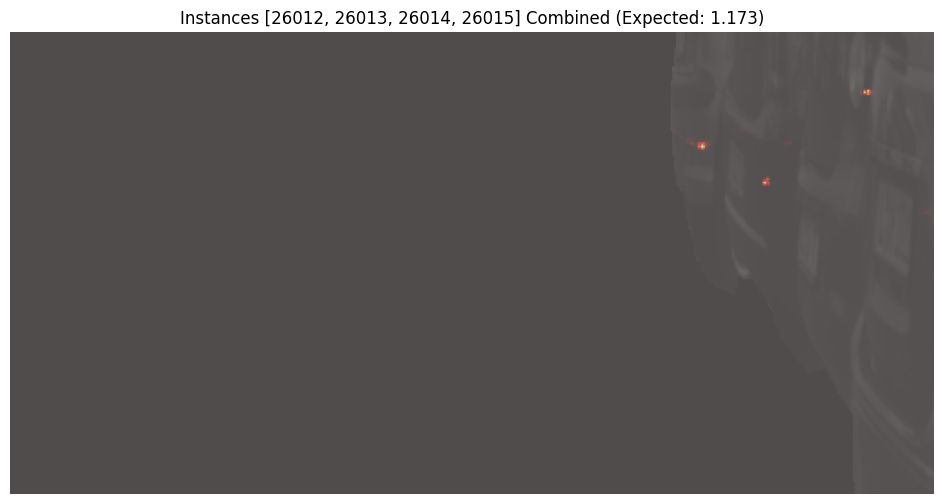

[{'instance_id': 26012,
  'area': 3754,
  'expected_count': 0.49429714994899415,
  'mean_intensity': 0.00013167212305513961},
 {'instance_id': 26013,
  'area': 6449,
  'expected_count': 0.3207347364475763,
  'mean_intensity': 4.9734026430078505e-05},
 {'instance_id': 26014,
  'area': 7060,
  'expected_count': 0.305730678193937,
  'mean_intensity': 4.330462863936785e-05},
 {'instance_id': 26015,
  'area': 9779,
  'expected_count': 0.052533235418164986,
  'mean_intensity': 5.372045752956845e-06},
 {'instance_id': [26012, 26013, 26014, 26015],
  'area': 27042,
  'expected_count': 1.1732958000086726,
  'mean_intensity': 4.338790769945539e-05,
  'combined': True}]

In [73]:
instance_ids = [26012, 26013, 26014, 26015]
evaluate_instances(img, heatmap, gt_inst, instance_ids)

In [12]:
def evaluate_boxes(img, logits, boxes, crop_size=(256,512), centers=None):
    """
    Evaluate bounding boxes using PPP intensity:
        λ = exp(f) / (H_full * W_full)
    """

    H, W = logits.shape
    pixel_area = crop_size[0] * crop_size[1]

    # convert logits -> PPP intensities λ(x)
    lam = np.exp(logits) / pixel_area

    results = []
    combined_mask = np.zeros((H, W), dtype=bool)

    # --- Evaluate each box individually ---
    for i, box in enumerate(boxes):
        x1, y1, x2, y2 = box

        # clip + sort coordinates safely
        x1, x2 = sorted((max(0, x1), min(W, x2)))
        y1, y2 = sorted((max(0, y1), min(H, y2)))

        # region mask
        mask = np.zeros((H, W), dtype=bool)
        mask[y1:y2, x1:x2] = True
        combined_mask |= mask

        region = lam[y1:y2, x1:x2]
        area = region.size
        integral = region.sum()
        mean_val = region.mean()

        results.append({
            "box_index": i,
            "box": (x1, y1, x2, y2),
            "area": int(area),
            "expected_count": float(integral),
            "mean_intensity": float(mean_val)
        })

    # --- Combined evaluation over union of all boxes ---
    if combined_mask.sum() > 0:
        region = lam[combined_mask]
        combined_integral = region.sum()
        combined_mean = region.mean()

        results.append({
            "box_index": "combined",
            "box": boxes,
            "area": int(region.size),
            "expected_count": float(combined_integral),
            "mean_intensity": float(combined_mean),
            "combined": True
        })

        overlay_heatmap(
            img,
            lam,   # show λ, not logits
            mask=combined_mask,
            centers=centers,
            title=f"Boxes Combined (Expected: {combined_integral:.3f})"
        )

    return results


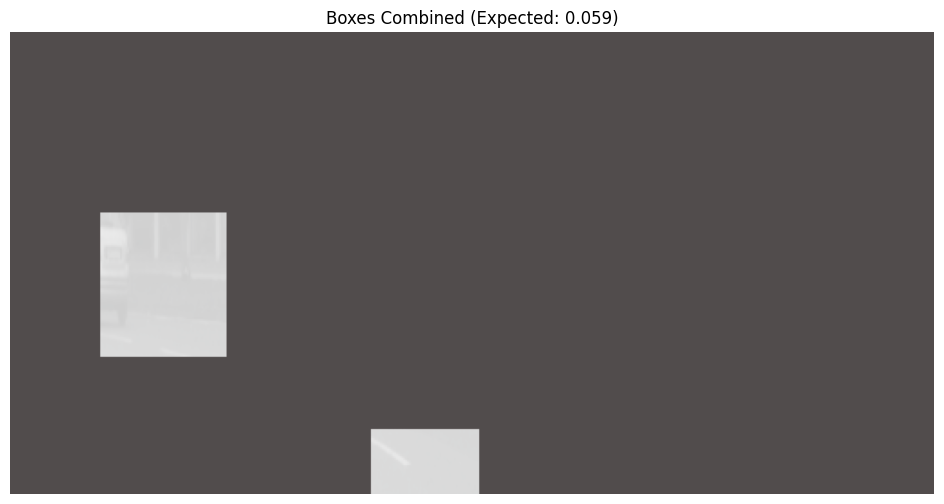

[{'box_index': 0,
  'box': (50, 100, 120, 180),
  'area': 5600,
  'expected_count': 0.042801898382094805,
  'mean_intensity': 7.643196139659787e-06},
 {'box_index': 1,
  'box': (200, 220, 260, 256),
  'area': 2160,
  'expected_count': 0.016509339867297967,
  'mean_intensity': 7.643212901526837e-06},
 {'box_index': 'combined',
  'box': [(50, 100, 120, 180), (200, 220, 260, 280)],
  'area': 7760,
  'expected_count': 0.05931123824939277,
  'mean_intensity': 7.64320080533412e-06,
  'combined': True}]

In [13]:
# (x1, y1, x2, y2) = (left, top, right, bottom)
boxes = [
    (50,100,120,180),
    (200,220,260,280)
]

evaluate_boxes(img, heatmap, boxes)
